# Query-aligned DDR teacher–student classification

This notebook implements the controlled experiment in two deliberately separate
stages.

1. **Score realizability.** On a dense grid, fit the continuous teacher score.
   This verifies that the correct-query model contains the teacher and measures
   the best-found approximation errors of the wrong-query and no-query models.
   It is a structural diagnostic, not a learning curve.
2. **Classification.** Generate hard labels from the sign of the teacher score,
   train with binary cross-entropy, and report held-out classification
   performance as a function of the number of training examples.

The implementation avoids the failure modes of the earlier version:

- teacher and student parameters are sampled from the same free-parameter prior;
- every reported teacher is selected only by predeclared balance and
  nonseparability criteria;
- folds are independent and warm starts never cross folds;
- optimization budgets are fixed before the reported test sets are evaluated;
- no run is accepted, rejected, or rerun using test performance;
- uncertainty is computed across independently sampled teachers, with folds
  averaged within each teacher;
- the primary result is balanced classification accuracy, not numerical
  reconstruction at floating-point precision.

The default smoke profile is intentionally small and tests the complete
pipeline. Set PROFILE = "paper" before producing manuscript results.

In [2]:
# =============================================================================
# Configuration
# =============================================================================
from dataclasses import dataclass
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from scipy.optimize import least_squares, minimize

jax.config.update("jax_enable_x64", True)

# "ry" is the deliberately minimal controlled model. It has eight trainable
# parameters at n_q=2 and should not be described as a full-SU(2) ansatz.
# "yzy" restores arbitrary single-qubit SU(2) factors.
N_QUBITS = 2
N_LAYERS = 2
BLOCK = "ry"
F_STAR_PAIR = np.array([np.pi / 4, np.pi / 3])
WRONG_SCALE = 2.0
BETA = 5.0

PROFILE = "paper"
PROFILES = {
    "smoke": dict(
        n_teachers=2,
        n_folds=5,
        n_grid=[8, 16, 32],
        n_test=1500,
        n_probe=5000,
        n_restarts=4,
        adam_steps=300,
        adam_lr=0.035,
        polish_top=1,
        polish_maxiter=120,
        score_restarts=4,
        score_max_nfev=250,
        bootstrap_samples=500,
    ),
    "paper": dict(
        n_teachers=10,
        n_folds=8,
        n_grid=[8, 16, 32, 64, 128, 256],
        n_test=10000,
        n_probe=20000,
        n_restarts=16,
        adam_steps=2000,
        adam_lr=0.03,
        polish_top=3,
        polish_maxiter=500,
        score_restarts=32,
        score_max_nfev=1000,
        bootstrap_samples=5000,
    ),
}
if PROFILE not in PROFILES:
    raise ValueError(f"unknown PROFILE={PROFILE!r}")
P = PROFILES[PROFILE]

TEACHER_SEEDS = list(range(P["n_teachers"]))
BALANCE = (0.4, 0.6)
MIN_NONSEP = 0.2
MAX_TEACHER_DRAWS = 4000
WARM_START_ACROSS_N = False
BASE_SEED = 1729

OUTDIR = Path("./teacher_student_outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

print(
    f"profile={PROFILE} | block={BLOCK} | teachers={P['n_teachers']} | "
    f"folds={P['n_folds']} | n={P['n_grid']}"
)
if PROFILE != "paper":
    print("SMOKE PROFILE: use PROFILE='paper' before reporting numerical results.")

profile=paper | block=ry | teachers=10 | folds=8 | n=[8, 16, 32, 64, 128, 256]


## Circuit and query family

For two qubits,

\[
U(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)
=
\prod_{\ell=1}^{2}
V_\ell(\boldsymbol\theta)
Q_\ell(\boldsymbol f)
W_\ell(\boldsymbol\theta)
E_x(\boldsymbol x),
\]

with \(E_x(\boldsymbol x)=R_{Z_0}(x_0)R_{Z_1}(x_1)\),
\((s_1,s_2)=(1,2)\), and

\[
Q_\ell(\boldsymbol f)
=
R_{Z_0Y_1}(s_\ell f_1)
R_{Y_0Z_1}(s_\ell f_0).
\]

The trainable blocks are products of single-qubit rotations. The correct and
wrong arms use the same nonlocal query encoding but different fixed values.
The no-query arm sets \(\boldsymbol f=\boldsymbol0\), for which the circuit
factorizes and the score is separable across \(x_0|x_1\).

In [3]:
# =============================================================================
# Circuit implementation
# =============================================================================
_I = np.eye(2, dtype=complex)
_Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
_Z = np.diag([1, -1]).astype(complex)


def rng_from(*parts):
    return np.random.default_rng(
        np.random.SeedSequence([int(part) for part in parts])
    )


@dataclass(frozen=True)
class Cfg:
    n_qubits: int = 2
    n_layers: int = 2
    block: str = "ry"

    def __post_init__(self):
        if self.n_qubits % 2:
            raise ValueError("the YZ/ZY dimer construction needs an even n_qubits")
        if self.block not in {"ry", "yzy"}:
            raise ValueError("block must be 'ry' or 'yzy'")

    @property
    def n_dimers(self):
        return self.n_qubits // 2

    @property
    def dimers(self):
        return [(2 * d, 2 * d + 1) for d in range(self.n_dimers)]

    @property
    def scales(self):
        return np.arange(1, self.n_layers + 1, dtype=float)

    @property
    def n_params(self):
        per_single_qubit = 1 if self.block == "ry" else 3
        return self.n_layers * 2 * self.n_qubits * per_single_qubit

    def expand(self, free_parameters):
        free_parameters = jnp.asarray(free_parameters).ravel()
        shape = (self.n_layers, 2, self.n_qubits)
        if self.block == "yzy":
            return free_parameters.reshape(*shape, 3)
        return jnp.zeros((*shape, 3)).at[:, :, :, 1].set(
            free_parameters.reshape(*shape)
        )

    def free(self, full_parameters):
        full = np.asarray(full_parameters).reshape(
            self.n_layers, 2, self.n_qubits, 3
        )
        if self.block == "yzy":
            return full.ravel()
        return full[:, :, :, 1].ravel()


CFG = Cfg(N_QUBITS, N_LAYERS, BLOCK)


def make_f_star(n_qubits):
    return np.tile(F_STAR_PAIR, n_qubits // 2).astype(float)


F_STAR = make_f_star(CFG.n_qubits)
ARMS = {
    "correct": F_STAR.copy(),
    "wrong": WRONG_SCALE * F_STAR,
    "none": np.zeros_like(F_STAR),
}


def kron_all_numpy(matrices):
    out = np.array([[1.0]], dtype=complex)
    for matrix in matrices:
        out = np.kron(out, matrix)
    return out


def query_generators(n_qubits):
    generators = []
    for i, j in [(2 * d, 2 * d + 1) for d in range(n_qubits // 2)]:
        for left, right in ((_Y, _Z), (_Z, _Y)):
            matrices = [_I] * n_qubits
            matrices[i], matrices[j] = left, right
            generators.append(kron_all_numpy(matrices))
    return generators


def maximum_generator_commutator(n_qubits):
    generators = query_generators(n_qubits)
    return max(
        float(np.max(np.abs(a @ b - b @ a)))
        for i, a in enumerate(generators)
        for b in generators[i + 1 :]
    )


def basis_signs(n_qubits):
    indices = np.arange(2**n_qubits)
    bits = (
        indices[:, None]
        >> np.arange(n_qubits - 1, -1, -1)[None, :]
    ) & 1
    return 1.0 - 2.0 * bits


def _su2_jax(parameters):
    a, b, c = parameters
    rz = lambda angle: jnp.diag(
        jnp.array(
            [jnp.exp(-0.5j * angle), jnp.exp(0.5j * angle)],
            dtype=jnp.complex128,
        )
    )
    cosine = jnp.cos(b / 2).astype(jnp.complex128)
    sine = jnp.sin(b / 2).astype(jnp.complex128)
    ry = jnp.array([[cosine, -sine], [sine, cosine]], dtype=jnp.complex128)
    return rz(c) @ ry @ rz(a)


def _kron_jax(matrices):
    out = jnp.eye(1, dtype=jnp.complex128)
    for matrix in matrices:
        out = jnp.kron(out, matrix)
    return out


def _query_jax(f, scale, cfg):
    yz = jnp.asarray(np.kron(_Y, _Z))
    zy = jnp.asarray(np.kron(_Z, _Y))
    identity = jnp.eye(4, dtype=jnp.complex128)

    def rotation(angle, generator):
        return (
            jnp.cos(angle / 2).astype(jnp.complex128) * identity
            - 1j * jnp.sin(angle / 2).astype(jnp.complex128) * generator
        )

    dimer_gates = []
    for dimer in range(cfg.n_dimers):
        f0, f1 = f[2 * dimer], f[2 * dimer + 1]
        dimer_gates.append(
            rotation(scale * f1, zy) @ rotation(scale * f0, yz)
        )
    return _kron_jax(dimer_gates)


def forward(full_parameters, x, f, cfg=CFG):
    dimension = 2**cfg.n_qubits
    signs = basis_signs(cfg.n_qubits)
    parity = jnp.asarray(np.prod(signs, axis=1))
    initial = jnp.full(
        (dimension,), 1.0 / np.sqrt(dimension), dtype=jnp.complex128
    )

    theta = jnp.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )
    x = jnp.atleast_2d(jnp.asarray(x))
    f = jnp.asarray(f)
    data_phase = jnp.exp(-0.5j * (x @ jnp.asarray(signs).T))

    state = jnp.broadcast_to(initial, (x.shape[0], dimension))
    for layer in range(cfg.n_layers):
        state = state * data_phase
        w_layer = _kron_jax(
            [_su2_jax(theta[layer, 0, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ w_layer.T
        state = state @ _query_jax(f, cfg.scales[layer], cfg).T
        v_layer = _kron_jax(
            [_su2_jax(theta[layer, 1, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ v_layer.T

    return jnp.real(jnp.sum(jnp.abs(state) ** 2 * parity, axis=1))


def sample_free_prior(rng, cfg=CFG):
    if cfg.block == "ry":
        return rng.uniform(-np.pi, np.pi, cfg.n_params)

    shape = (cfg.n_layers, 2, cfg.n_qubits)
    a = rng.uniform(0.0, 2 * np.pi, shape)
    c = rng.uniform(0.0, 2 * np.pi, shape)
    b = np.arccos(1.0 - 2.0 * rng.uniform(0.0, 1.0, shape))
    return np.stack([a, b, c], axis=-1).ravel()


def fourier_matrix(full_parameters, f, cfg=CFG, dimer=0):
    modes_per_axis = 2 * cfg.n_layers + 1
    sub_cfg = Cfg(2, cfg.n_layers, cfg.block)
    i, j = cfg.dimers[dimer]
    theta = np.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )[:, :, [i, j], :]
    f_sub = np.asarray(f)[[i, j]]
    grid = 2 * np.pi * np.arange(modes_per_axis) / modes_per_axis
    x0, x1 = np.meshgrid(grid, grid, indexing="ij")
    points = np.stack([x0.ravel(), x1.ravel()], axis=1)
    values = np.asarray(forward(theta, points, f_sub, sub_cfg)).reshape(
        modes_per_axis, modes_per_axis
    )
    return np.fft.fftshift(
        np.fft.fft2(values) / modes_per_axis**2
    )


def coefficient_nonseparability(full_parameters, f, cfg=CFG):
    result = {}
    for dimer in range(cfg.n_dimers):
        singular_values = np.linalg.svd(
            fourier_matrix(full_parameters, f, cfg, dimer),
            compute_uv=False,
        )
        result[f"dimer{dimer}"] = float(
            1.0
            - singular_values[0] ** 2
            / np.sum(singular_values**2)
        )
    result["min"] = min(
        result[f"dimer{d}"] for d in range(cfg.n_dimers)
    )
    return result


def operator_nonseparable_weight(gate):
    reshuffled = (
        np.asarray(gate)
        .reshape(2, 2, 2, 2)
        .transpose(0, 2, 1, 3)
        .reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))


assert maximum_generator_commutator(CFG.n_qubits) < 1e-12
unit_rng = rng_from(BASE_SEED, 1)
unit_w = sample_free_prior(unit_rng, CFG)
unit_theta = np.asarray(CFG.expand(unit_w))
unit_x = unit_rng.uniform(0, 2 * np.pi, (64, CFG.n_qubits))
unit_values = np.asarray(forward(unit_theta, unit_x, F_STAR, CFG))
assert np.max(np.abs(unit_values)) <= 1.0 + 1e-10
assert coefficient_nonseparability(
    unit_theta, np.zeros_like(F_STAR), CFG
)["min"] < 1e-10
generic_query = np.asarray(_query_jax(F_STAR, 1.0, CFG))
if CFG.n_qubits == 2:
    assert operator_nonseparable_weight(generic_query) > 1e-3

print(
    f"circuit checks passed | n_params={CFG.n_params} | "
    f"f*={np.round(F_STAR, 4)} | wrong={np.round(ARMS['wrong'], 4)}"
)

circuit checks passed | n_params=8 | f*=[0.7854 1.0472] | wrong=[1.5708 2.0944]


## Teacher ensemble

Each teacher is sampled from the same free-parameter prior used for student
initialization. We retain the first draw satisfying two predeclared conditions:
approximately balanced labels and a nonseparable coefficient matrix. This
conditioning is intentional and is recorded for every teacher; it constructs a
controlled task in which the no-query separable endpoint is genuinely
misspecified.

Teacher selection uses an independent probe set. No reported training or test
example participates in selection.

In [4]:
# =============================================================================
# Teacher selection
# =============================================================================
def select_teacher(
    cfg,
    f_star,
    teacher_seed,
    *,
    n_probe,
    balance=BALANCE,
    min_nonsep=MIN_NONSEP,
    max_draws=MAX_TEACHER_DRAWS,
):
    probe_rng = rng_from(BASE_SEED, 100, teacher_seed)
    parameter_rng = rng_from(BASE_SEED, 101, teacher_seed)
    x_probe = probe_rng.uniform(
        0, 2 * np.pi, (n_probe, cfg.n_qubits)
    )

    for draw in range(1, max_draws + 1):
        free_parameters = sample_free_prior(parameter_rng, cfg)
        full_parameters = np.asarray(cfg.expand(free_parameters))
        score = np.asarray(forward(full_parameters, x_probe, f_star, cfg))
        positive_fraction = float(np.mean(score > 0))
        if not (balance[0] < positive_fraction < balance[1]):
            continue

        nonseparability = coefficient_nonseparability(
            full_parameters, f_star, cfg
        )
        if nonseparability["min"] <= min_nonsep:
            continue

        return {
            "teacher": int(teacher_seed),
            "draws": int(draw),
            "free_parameters": np.asarray(free_parameters),
            "full_parameters": full_parameters,
            "balance": positive_fraction,
            "nonseparability": nonseparability,
            "boundary_mass_005": float(np.mean(np.abs(score) < 0.05)),
        }

    raise RuntimeError(
        f"teacher {teacher_seed} did not pass the predeclared criteria "
        f"in {max_draws} draws"
    )


t0 = time.time()
TEACHERS = [
    select_teacher(
        CFG,
        F_STAR,
        seed,
        n_probe=P["n_probe"],
    )
    for seed in TEACHER_SEEDS
]

teacher_table = pd.DataFrame(
    [
        {
            "teacher": t["teacher"],
            "draws": t["draws"],
            "balance": t["balance"],
            "nonseparability": t["nonseparability"]["min"],
            "boundary_mass_005": t["boundary_mass_005"],
        }
        for t in TEACHERS
    ]
)
print(teacher_table.to_string(index=False))
print(f"selected {len(TEACHERS)} teachers in {time.time() - t0:.1f}s")

 teacher  draws  balance  nonseparability  boundary_mass_005
       0      1  0.44610         0.252383            0.08915
       1      5  0.43815         0.595118            0.11495
       2      2  0.51450         0.271047            0.04985
       3      1  0.53520         0.467105            0.09780
       4      5  0.52015         0.521541            0.08865
       5      4  0.43140         0.509167            0.06320
       6      3  0.44020         0.522358            0.10470
       7      3  0.49605         0.322941            0.06630
       8      4  0.42420         0.545583            0.09600
       9      1  0.48375         0.596251            0.06025
selected 10 teachers in 0.7s


## Stage A — score-realizability diagnostic

This stage uses the continuous teacher score on a dense, independently
constructed grid. It is not a classification experiment and does not use the
reported test sets.

For every teacher and arm, a fixed number of trust-region least-squares fits is
performed from paired initial parameters. The known teacher parameters are
included as one common start for all arms. Thus the correct arm provides a
numerical implementation check, while the other values are explicitly
best-found approximation errors rather than proofs of nonrepresentability.
The no-query obstruction is independently certified by separability.

In [13]:
# =============================================================================
# Continuous-score realizability
# =============================================================================
def score_fit(
    cfg,
    f,
    x,
    target,
    starts,
    *,
    max_nfev,
):
    x_jax = jnp.asarray(x)
    f_jax = jnp.asarray(f)
    target_jax = jnp.asarray(target)

    prediction = lambda w: forward(cfg.expand(w), x_jax, f_jax, cfg)
    residual = jax.jit(lambda w: prediction(w) - target_jax)
    jacobian = jax.jit(jax.jacfwd(prediction))

    best_loss = np.inf
    best_parameters = None
    for start in starts:
        result = least_squares(
            lambda w: np.asarray(residual(jnp.asarray(w))),
            np.asarray(start),
            jac=lambda w: np.asarray(jacobian(jnp.asarray(w))),
            method="trf",
            xtol=1e-12,
            ftol=1e-12,
            gtol=1e-12,
            max_nfev=max_nfev,
        )
        loss = float(np.mean(result.fun**2))
        if loss < best_loss:
            best_loss = loss
            best_parameters = np.asarray(result.x)

    prediction_best = np.asarray(
        forward(cfg.expand(best_parameters), x, f, cfg)
    )
    relative_mse = float(
        np.mean((prediction_best - target) ** 2)
        / np.mean(np.asarray(target) ** 2)
    )
    return {
        "mse": best_loss,
        "relative_mse": relative_mse,
    }


def diagnostic_grid(n_qubits, points_per_axis=15):
    if n_qubits != 2:
        raise ValueError(
            "the dense Cartesian diagnostic grid is intentionally limited "
            "to the reported two-qubit experiment"
        )
    grid = 2 * np.pi * np.arange(points_per_axis) / points_per_axis
    x0, x1 = np.meshgrid(grid, grid, indexing="ij")
    return np.stack([x0.ravel(), x1.ravel()], axis=1)


def run_score_diagnostic(cfg, teachers, arms):
    x = diagnostic_grid(cfg.n_qubits)
    rows = []
    for teacher in teachers:
        target = np.asarray(
            forward(
                teacher["full_parameters"],
                x,
                F_STAR,
                cfg,
            )
        )
        start_rng = rng_from(BASE_SEED, 200, teacher["teacher"])
        starts = [teacher["free_parameters"].copy()]
        starts.extend(
            sample_free_prior(start_rng, cfg)
            for _ in range(P["score_restarts"] - 1)
        )
        for arm, f in arms.items():
            fit = score_fit(
                cfg,
                f,
                x,
                target,
                starts,
                max_nfev=P["score_max_nfev"],
            )
            rows.append(
                {
                    "teacher": teacher["teacher"],
                    "arm": arm,
                    **fit,
                }
            )
    return pd.DataFrame(rows)


t0 = time.time()
SCORE_RESULTS = run_score_diagnostic(CFG, TEACHERS, ARMS)
print(
    SCORE_RESULTS.pivot_table(
        index="arm", values="relative_mse", aggfunc=["median", "min", "max"]
    )
)
print(f"score diagnostic completed in {time.time() - t0:.1f}s")

              median          min          max
        relative_mse relative_mse relative_mse
arm                                           
correct     0.000000     0.000000     0.000000
none        0.544034     0.252447     0.649138
wrong       0.131560     0.031430     0.240101
score diagnostic completed in 43.9s


## Stage B — classification learning curves

Labels are

\[
y(\boldsymbol x)=\mathbb{1}[v^\star(\boldsymbol x)>0].
\]

Each student predicts

\[
p_{\boldsymbol\theta}(y=1\mid\boldsymbol x)
=\sigma\!\left[\beta
v(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)\right],
\qquad \beta=5,
\]

and is trained by binary cross-entropy. There is no trainable classical
readout. All arms receive identical training points and paired initial
parameters. Optimization uses a fixed number of full-batch Adam steps followed
by a fixed L-BFGS polishing budget for the best Adam starts. Model selection
uses training BCE only.

Reported test sets are generated only after teacher selection and are never
used to choose starts, budgets, hyperparameters, or accepted runs.

In [6]:
# =============================================================================
# Classification optimizer and metrics
# =============================================================================
def bce_from_logits(logits, labels):
    labels = jnp.asarray(labels)
    return jnp.mean(jax.nn.softplus(logits) - labels * logits)


def classification_loss(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    score = forward(cfg.expand(free_parameters), x, f, cfg)
    return bce_from_logits(beta * score, labels)


def make_batched_adam(
    cfg,
    *,
    beta,
    n_steps,
    learning_rate,
    gradient_clip=10.0,
):
    def loss_one(parameters, x, labels, f):
        return classification_loss(parameters, x, labels, f, cfg, beta)

    value_and_gradient = jax.vmap(
        jax.value_and_grad(loss_one),
        in_axes=(0, None, None, None),
    )

    @jax.jit
    def run(initial_parameters, x, labels, f):
        parameters = jnp.asarray(initial_parameters)
        first_moment = jnp.zeros_like(parameters)
        second_moment = jnp.zeros_like(parameters)

        def body(step, state):
            parameters, first_moment, second_moment = state
            _, gradient = value_and_gradient(parameters, x, labels, f)

            norms = jnp.linalg.norm(gradient, axis=1, keepdims=True)
            gradient = gradient * jnp.minimum(
                1.0, gradient_clip / (norms + 1e-12)
            )

            first_moment = 0.9 * first_moment + 0.1 * gradient
            second_moment = 0.999 * second_moment + 0.001 * gradient**2
            t = step + 1
            first_corrected = first_moment / (1.0 - 0.9**t)
            second_corrected = second_moment / (1.0 - 0.999**t)

            fraction = step / jnp.maximum(1, n_steps - 1)
            rate = learning_rate * (
                0.1 + 0.9 * 0.5 * (1.0 + jnp.cos(jnp.pi * fraction))
            )
            parameters = parameters - rate * first_corrected / (
                jnp.sqrt(second_corrected) + 1e-8
            )
            return parameters, first_moment, second_moment

        parameters, _, _ = jax.lax.fori_loop(
            0,
            n_steps,
            body,
            (parameters, first_moment, second_moment),
        )
        losses = jax.vmap(loss_one, in_axes=(0, None, None, None))(
            parameters, x, labels, f
        )
        return parameters, losses

    return run


ADAM_RUNNER = make_batched_adam(
    CFG,
    beta=BETA,
    n_steps=P["adam_steps"],
    learning_rate=P["adam_lr"],
)


def balanced_accuracy(labels, predictions):
    labels = np.asarray(labels, dtype=bool)
    predictions = np.asarray(predictions, dtype=bool)
    positive = labels
    negative = ~labels
    if not np.any(positive) or not np.any(negative):
        return np.nan
    sensitivity = np.mean(predictions[positive])
    specificity = np.mean(~predictions[negative])
    return float(0.5 * (sensitivity + specificity))


def evaluate_classifier(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    score = np.asarray(forward(cfg.expand(free_parameters), x, f, cfg))
    logits = beta * score
    labels = np.asarray(labels, dtype=float)
    predictions = logits > 0
    bce = float(
        np.mean(np.logaddexp(0.0, logits) - labels * logits)
    )
    return {
        "bce": bce,
        "accuracy": float(np.mean(predictions == labels)),
        "balanced_accuracy": balanced_accuracy(labels, predictions),
    }


def fit_classifier(
    cfg,
    f,
    x_train,
    y_train,
    x_test,
    y_test,
    *,
    seed,
    extra_start=None,
):
    rng = rng_from(BASE_SEED, 300, seed)
    initial = np.stack(
        [sample_free_prior(rng, cfg) for _ in range(P["n_restarts"])]
    )
    if extra_start is not None:
        initial[0] = np.asarray(extra_start)

    adam_parameters, adam_losses = ADAM_RUNNER(
        jnp.asarray(initial),
        jnp.asarray(x_train),
        jnp.asarray(y_train),
        jnp.asarray(f),
    )
    candidates = np.asarray(adam_parameters)
    losses = np.asarray(adam_losses)
    best_index = int(np.argmin(losses))
    best_parameters = candidates[best_index].copy()
    best_loss = float(losses[best_index])

    x_jax = jnp.asarray(x_train)
    y_jax = jnp.asarray(y_train)
    f_jax = jnp.asarray(f)
    objective = jax.jit(
        jax.value_and_grad(
            lambda w: classification_loss(w, x_jax, y_jax, f_jax, cfg, BETA)
        )
    )

    def value_and_jacobian(parameters):
        value, gradient = objective(jnp.asarray(parameters))
        return float(value), np.asarray(gradient, dtype=float)

    polish_indices = np.argsort(losses)[: P["polish_top"]]
    polish_successes = 0
    for index in polish_indices:
        result = minimize(
            value_and_jacobian,
            candidates[index],
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": P["polish_maxiter"],
                "ftol": 1e-12,
                "gtol": 1e-9,
            },
        )
        if result.success:
            polish_successes += 1
        if float(result.fun) < best_loss:
            best_loss = float(result.fun)
            best_parameters = np.asarray(result.x)

    train_metrics = evaluate_classifier(
        best_parameters, x_train, y_train, f, cfg
    )
    test_metrics = evaluate_classifier(
        best_parameters, x_test, y_test, f, cfg
    )
    return {
        "free_parameters": best_parameters,
        "train_bce": train_metrics["bce"],
        "train_accuracy": train_metrics["accuracy"],
        "train_balanced_accuracy": train_metrics["balanced_accuracy"],
        "test_bce": test_metrics["bce"],
        "test_accuracy": test_metrics["accuracy"],
        "test_balanced_accuracy": test_metrics["balanced_accuracy"],
        "polish_successes": int(polish_successes),
    }

In [15]:
# =============================================================================
# Paired classification experiment
# =============================================================================
def run_classification_experiment(cfg, teachers, arms):
    rows = []
    n_max = max(P["n_grid"])

    for teacher in teachers:
        teacher_id = teacher["teacher"]
        theta_star = teacher["full_parameters"]

        test_rng = rng_from(BASE_SEED, 400, teacher_id)
        x_test = test_rng.uniform(
            0, 2 * np.pi, (P["n_test"], cfg.n_qubits)
        )
        teacher_test_score = np.asarray(
            forward(theta_star, x_test, F_STAR, cfg)
        )
        y_test = (teacher_test_score > 0).astype(float)

        for fold in range(P["n_folds"]):
            # Warm starts are reset for every independent fold.
            warm = {}
            pool_rng = rng_from(BASE_SEED, 401, teacher_id, fold)
            x_pool = pool_rng.uniform(
                0, 2 * np.pi, (n_max, cfg.n_qubits)
            )
            teacher_pool_score = np.asarray(
                forward(theta_star, x_pool, F_STAR, cfg)
            )
            y_pool = (teacher_pool_score > 0).astype(float)

            for n in sorted(P["n_grid"]):
                x_train = x_pool[:n]
                y_train = y_pool[:n]
                paired_seed = (
                    1_000_000 * teacher_id + 10_000 * fold + int(n)
                )

                message = []
                for arm, f in arms.items():
                    result = fit_classifier(
                        cfg,
                        f,
                        x_train,
                        y_train,
                        x_test,
                        y_test,
                        seed=paired_seed,
                        extra_start=(
                            warm.get(arm)
                            if WARM_START_ACROSS_N
                            else None
                        ),
                    )
                    if WARM_START_ACROSS_N:
                        warm[arm] = result["free_parameters"]

                    rows.append(
                        {
                            "teacher": int(teacher_id),
                            "fold": int(fold),
                            "n": int(n),
                            "arm": arm,
                            **{
                                key: value
                                for key, value in result.items()
                                if key != "free_parameters"
                            },
                        }
                    )
                    message.append(
                        f"{arm}:{result['test_balanced_accuracy']:.3f}"
                    )

                print(
                    f"teacher={teacher_id:02d} fold={fold:02d} n={n:03d} | "
                    + " ".join(message),
                    flush=True,
                )

    return pd.DataFrame(rows)


t0 = time.time()
CLASSIFICATION_RESULTS = run_classification_experiment(
    CFG, TEACHERS, ARMS
)
print(f"classification experiment completed in {time.time() - t0:.1f}s")

teacher=00 fold=00 n=008 | correct:0.625 wrong:0.516 none:0.722
teacher=00 fold=00 n=016 | correct:0.662 wrong:0.670 none:0.652
teacher=00 fold=00 n=032 | correct:0.821 wrong:0.807 none:0.737
teacher=00 fold=00 n=064 | correct:0.906 wrong:0.852 none:0.779
teacher=00 fold=00 n=128 | correct:0.932 wrong:0.839 none:0.749
teacher=00 fold=00 n=256 | correct:0.936 wrong:0.858 none:0.754
teacher=00 fold=01 n=008 | correct:0.663 wrong:0.635 none:0.754
teacher=00 fold=01 n=016 | correct:0.781 wrong:0.775 none:0.750
teacher=00 fold=01 n=032 | correct:0.823 wrong:0.776 none:0.744
teacher=00 fold=01 n=064 | correct:0.877 wrong:0.830 none:0.732
teacher=00 fold=01 n=128 | correct:0.908 wrong:0.854 none:0.755
teacher=00 fold=01 n=256 | correct:0.919 wrong:0.892 none:0.777
teacher=00 fold=02 n=008 | correct:0.605 wrong:0.594 none:0.758
teacher=00 fold=02 n=016 | correct:0.784 wrong:0.782 none:0.724
teacher=00 fold=02 n=032 | correct:0.794 wrong:0.739 none:0.757
teacher=00 fold=02 n=064 | correct:0.924

## Aggregation and figures

Folds are first averaged within each teacher. Uncertainty is then obtained by
resampling teachers, preserving the pairing of all arms and sample sizes.
Consequently, the interval reflects variation across independently generated
tasks rather than treating folds from the same teacher as independent tasks.

The smoke profile contains too few teachers for inferential uncertainty; its
interval is only a pipeline check.

In [5]:
# =============================================================================
# Paired teacher-level aggregation
# =============================================================================
PRIMARY_METRIC = "test_balanced_accuracy"


def teacher_level_table(results, metric):
    return (
        results.groupby(["teacher", "arm", "n"], as_index=False)[metric]
        .mean()
        .sort_values(["teacher", "arm", "n"])
    )


def paired_teacher_bootstrap(
    results,
    metric,
    *,
    n_bootstrap,
    seed=0,
):
    table = teacher_level_table(results, metric)
    teachers = np.array(sorted(table["teacher"].unique()))
    arms = list(ARMS)
    sample_sizes = sorted(table["n"].unique())

    values = np.empty((len(teachers), len(arms), len(sample_sizes)))
    for i, teacher in enumerate(teachers):
        for j, arm in enumerate(arms):
            part = table[
                (table["teacher"] == teacher) & (table["arm"] == arm)
            ].set_index("n")
            values[i, j] = part.loc[sample_sizes, metric]

    estimate = values.mean(axis=0)
    rng = rng_from(BASE_SEED, 500, seed)
    bootstrap = np.empty(
        (n_bootstrap, len(arms), len(sample_sizes))
    )
    for draw in range(n_bootstrap):
        indices = rng.integers(0, len(teachers), len(teachers))
        bootstrap[draw] = values[indices].mean(axis=0)

    lower, upper = np.quantile(bootstrap, [0.025, 0.975], axis=0)
    return {
        "teachers": teachers,
        "arms": arms,
        "n": sample_sizes,
        "estimate": estimate,
        "lower": lower,
        "upper": upper,
        "bootstrap": bootstrap,
    }


SUMMARY = paired_teacher_bootstrap(
    CLASSIFICATION_RESULTS,
    PRIMARY_METRIC,
    n_bootstrap=P["bootstrap_samples"],
)

summary_rows = []
for arm_index, arm in enumerate(SUMMARY["arms"]):
    for n_index, n in enumerate(SUMMARY["n"]):
        summary_rows.append(
            {
                "arm": arm,
                "n": n,
                "mean": SUMMARY["estimate"][arm_index, n_index],
                "lower95": SUMMARY["lower"][arm_index, n_index],
                "upper95": SUMMARY["upper"][arm_index, n_index],
            }
        )
SUMMARY_TABLE = pd.DataFrame(summary_rows)
print(SUMMARY_TABLE.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


def paired_difference_at_largest_n(results, left="correct", right="wrong"):
    n = max(results["n"])
    table = teacher_level_table(results, PRIMARY_METRIC)
    pivot = (
        table[table["n"] == n]
        .pivot(index="teacher", columns="arm", values=PRIMARY_METRIC)
    )
    difference = np.asarray(pivot[left] - pivot[right])
    rng = rng_from(BASE_SEED, 501, len(right))
    bootstrap = np.array(
        [
            np.mean(
                difference[
                    rng.integers(0, len(difference), len(difference))
                ]
            )
            for _ in range(P["bootstrap_samples"])
        ]
    )
    return {
        "n": int(n),
        "mean": float(np.mean(difference)),
        "lower95": float(np.quantile(bootstrap, 0.025)),
        "upper95": float(np.quantile(bootstrap, 0.975)),
    }


for comparison in [("correct", "wrong"), ("correct", "none")]:
    effect = paired_difference_at_largest_n(
        CLASSIFICATION_RESULTS, *comparison
    )
    print(
        f"{comparison[0]} - {comparison[1]} at n={effect['n']}: "
        f"{effect['mean']:+.4f} "
        f"[{effect['lower95']:+.4f}, {effect['upper95']:+.4f}]"
    )

NameError: name 'CLASSIFICATION_RESULTS' is not defined

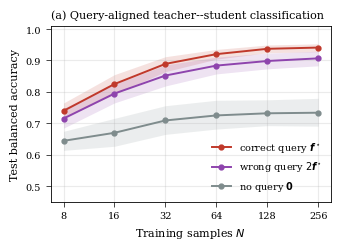

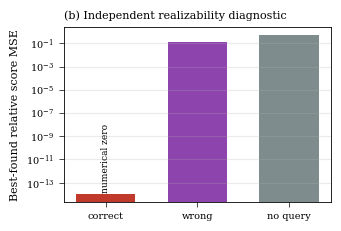

In [17]:
# =============================================================================
# Manuscript-style plots
# =============================================================================
COLORS = {
    "correct": "#C0392B",
    "wrong": "#8E44AD",
    "none": "#7F8C8D",
}
LABELS = {
    "correct": r"correct query $\boldsymbol{f}^\star$",
    "wrong": r"wrong query $2\boldsymbol{f}^\star$",
    "none": r"no query $\boldsymbol{0}$",
}

mpl.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "axes.linewidth": 0.6,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "lines.linewidth": 1.4,
        "legend.fontsize": 7,
    }
)

fig, axis = plt.subplots(figsize=(3.45, 2.55))
for arm_index, arm in enumerate(SUMMARY["arms"]):
    n = np.asarray(SUMMARY["n"])
    mean = SUMMARY["estimate"][arm_index]
    lower = SUMMARY["lower"][arm_index]
    upper = SUMMARY["upper"][arm_index]
    axis.plot(n, mean, "-o", color=COLORS[arm], label=LABELS[arm], ms=3.5)
    axis.fill_between(n, lower, upper, color=COLORS[arm], alpha=0.15, lw=0)

axis.set_xscale("log", base=2)
axis.set_xticks(SUMMARY["n"])
axis.set_xticklabels([str(n) for n in SUMMARY["n"]])
axis.set_ylim(0.45, 1.01)
axis.set_xlabel("Training samples $N$")
axis.set_ylabel("Test balanced accuracy")
axis.grid(True, which="major", alpha=0.25)
axis.legend(frameon=False)
axis.set_title("(a) Query-aligned teacher--student classification", loc="left")
fig.tight_layout()

classification_stem = OUTDIR / f"classification_{PROFILE}"
fig.savefig(classification_stem.with_suffix(".png"), dpi=300)
fig.savefig(classification_stem.with_suffix(".pdf"))
plt.show()


# Values below the display floor are labelled as numerical zero; no
# floating-point order-of-magnitude gap is claimed.
score_teacher_level = (
    SCORE_RESULTS.groupby("arm", as_index=False)["relative_mse"].median()
    .set_index("arm")
    .reindex(list(ARMS))
)
display_floor = 1e-14
display_values = np.maximum(
    score_teacher_level["relative_mse"].to_numpy(), display_floor
)

fig, axis = plt.subplots(figsize=(3.45, 2.35))
positions = np.arange(len(ARMS))
axis.bar(
    positions,
    display_values,
    color=[COLORS[arm] for arm in ARMS],
    width=0.65,
)
axis.set_yscale("log")
axis.set_xticks(positions)
axis.set_xticklabels(["correct", "wrong", "no query"])
axis.set_ylabel("Best-found relative score MSE")
axis.set_title("(b) Independent realizability diagnostic", loc="left")
axis.grid(True, axis="y", alpha=0.25)
for position, value in zip(
    positions, score_teacher_level["relative_mse"].to_numpy()
):
    if value < display_floor:
        axis.text(
            position,
            display_floor * 1.3,
            "numerical zero",
            ha="center",
            va="bottom",
            fontsize=6.5,
            rotation=90,
        )
fig.tight_layout()

score_stem = OUTDIR / f"score_realizability_{PROFILE}"
fig.savefig(score_stem.with_suffix(".png"), dpi=300)
fig.savefig(score_stem.with_suffix(".pdf"))
plt.show()

NameError: name 'SUMMARY' is not defined

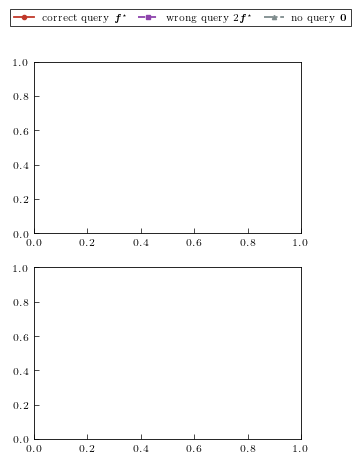

In [8]:
# =============================================================================
# Manuscript-style plots, restyled to match the two-panel reference figure:
# single column, panels stacked, shared framed legend on top, bold panel
# letters, major/minor gridlines, inward ticks, usetex with mathtext fallback.
# =============================================================================

import os
import shutil
import subprocess

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# -----------------------------------------------------------------------------
# LaTeX probing: honour USE_TEX=1 only if this installation can actually serve
# it, otherwise fall back to mathtext with the Computer Modern font set.
# -----------------------------------------------------------------------------

def latex_is_usable():
    if shutil.which("latex") is None or shutil.which("dvipng") is None:
        return False
    try:
        completed = subprocess.run(
            ["kpsewhich", "latex.ltx"],
            capture_output=True,
            timeout=30,
            check=False,
        )
    except (OSError, subprocess.SubprocessError):
        return False
    return completed.returncode == 0 and bool(completed.stdout.strip())


USE_TEX_REQUESTED = os.environ.get("USE_TEX", "1") == "1"
USE_TEX = USE_TEX_REQUESTED and latex_is_usable()
DASH = "--" if USE_TEX else "\u2013"


# -----------------------------------------------------------------------------
# Series appearance. Colour and dash pattern both carry the arm identity, so
# the panels stay readable in greyscale and for colour-vision deficiency.
# -----------------------------------------------------------------------------

COLORS = {
    "correct": "#C0392B",
    "wrong": "#8E44AD",
    "none": "#7F8C8D",
}
STYLE = {
    "correct": "-",
    "wrong": (0, (4, 2)),
    "none": (0, (5, 1.5, 1, 1.5)),
}
MARKER = {"correct": "o", "wrong": "s", "none": "^"}
LABELS = {
    "correct": r"correct query $\boldsymbol{f}^\star$",
    "wrong": r"wrong query $2\boldsymbol{f}^\star$",
    "none": r"no query $\boldsymbol{0}$",
}
BAND_ALPHA = {"correct": 0.14, "wrong": 0.13, "none": 0.12}
LEGEND_ORDER = ("correct", "wrong", "none")


def configure_matplotlib():
    """Compact single-column paper styling."""
    mpl.rcParams.update(
        {
            "text.usetex": USE_TEX,
            "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}",
            "font.family": "serif",
            "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
            "mathtext.fontset": "cm",
            "font.size": 8,
            "axes.labelsize": 8,
            "axes.titlesize": 8,
            "axes.linewidth": 0.6,
            "axes.spines.top": True,
            "axes.spines.right": True,
            "xtick.labelsize": 7.5,
            "ytick.labelsize": 7.5,
            "xtick.major.width": 0.5,
            "ytick.major.width": 0.5,
            "xtick.minor.width": 0.4,
            "ytick.minor.width": 0.4,
            "xtick.direction": "in",
            "ytick.direction": "in",
            "legend.fontsize": 6.9,
            "legend.handlelength": 2.1,
            "legend.columnspacing": 1.2,
            "lines.linewidth": 1.3,
            "savefig.bbox": None,
        }
    )


def panel_title(axis, letter, description):
    """Bold panel letter on the left, description on the right."""
    axis.set_title(letter, loc="left", pad=4, fontweight="bold")
    axis.set_title(description, loc="right", pad=4, fontsize=7.0, color="0.25")


def finish_axis(axis, x_minor=True, y_minor=True, grid_axis="both"):
    """Gridlines, minor ticks and spines, applied identically to every panel."""
    axis.set_axisbelow(True)
    axis.minorticks_on()
    if not x_minor:
        axis.xaxis.set_minor_locator(mticker.NullLocator())
    if not y_minor:
        axis.yaxis.set_minor_locator(mticker.NullLocator())
    axis.tick_params(which="both", top=False, right=False)
    axis.grid(True, which="major", axis=grid_axis, linestyle="-", alpha=0.30)
    axis.grid(True, which="minor", axis=grid_axis, linestyle=":", alpha=0.15)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)


# =============================================================================
# Figure
# =============================================================================

configure_matplotlib()
fig, axes = plt.subplots(2, 1, figsize=(3.45, 4.90))

handles = [
    Line2D(
        [],
        [],
        color=COLORS[arm],
        ls=STYLE[arm],
        marker=MARKER[arm],
        ms=3.0,
        label=LABELS[arm],
    )
    for arm in LEGEND_ORDER
]
legend = fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.55, 0.997),
    ncol=3,
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
)
legend.get_frame().set_linewidth(0.6)


# (a) Query-aligned teacher-student classification
axis = axes[0]
sample_counts = np.asarray(SUMMARY["n"])
for arm_index, arm in enumerate(SUMMARY["arms"]):
    mean = np.asarray(SUMMARY["estimate"][arm_index])
    lower = np.asarray(SUMMARY["lower"][arm_index])
    upper = np.asarray(SUMMARY["upper"][arm_index])
    axis.plot(
        sample_counts,
        mean,
        color=COLORS[arm],
        ls=STYLE[arm],
        marker=MARKER[arm],
        ms=3.0,
        mew=0.0,
    )
    axis.fill_between(
        sample_counts,
        lower,
        upper,
        color=COLORS[arm],
        alpha=BAND_ALPHA[arm],
        linewidth=0,
    )

axis.set_xscale("log", base=2)
axis.set_xticks(SUMMARY["n"])
axis.set_xticklabels([str(n) for n in SUMMARY["n"]])
axis.set_ylim(0.45, 1.01)
axis.set_xlabel(r"Training samples $N_{train}$")
axis.set_ylabel("Test balanced accuracy")
panel_title(axis, "(a)", f"Teacher{DASH}student classification")
# Fixed decade ticks on the log-2 axis; minor log ticks would clutter it.
finish_axis(axis, x_minor=False)


# (b) Independent realizability diagnostic.
# Values below the display floor are labelled as numerical zero; no
# floating-point order-of-magnitude gap is claimed.
score_teacher_level = (
    SCORE_RESULTS.groupby("arm", as_index=False)["relative_mse"]
    .median()
    .set_index("arm")
    .reindex(list(ARMS))
)
display_floor = 1e-14
raw_values = score_teacher_level["relative_mse"].to_numpy()
display_values = np.maximum(raw_values, display_floor)

axis = axes[1]
positions = np.arange(len(ARMS))
axis.bar(
    positions,
    display_values,
    color=[COLORS[arm] for arm in ARMS],
    width=0.62,
    edgecolor="black",
    linewidth=0.5,
    zorder=2,
)
axis.set_yscale("log")
axis.set_xticks(positions)
axis.set_xticklabels(["correct", "wrong", "no query"])
axis.set_xlim(-0.6, len(ARMS) - 0.4)
axis.set_ylabel("Best-found relative score MSE")
panel_title(axis, "(b)", "Independent realizability diagnostic")
# Horizontal rules only: vertical gridlines behind bars read as clutter.
finish_axis(axis, x_minor=False, grid_axis="y")

for position, value in zip(positions, raw_values):
    if value < display_floor:
        axis.text(
            position,
            display_floor * 1.4,
            "numerical zero",
            ha="center",
            va="bottom",
            fontsize=6.6,
            rotation=90,
            color="0.25",
            zorder=3,
        )

fig.subplots_adjust(
    left=0.165,
    right=0.985,
    bottom=0.078,
    top=0.918,
    hspace=0.40,
)

output_stem = f"query_encoding_summary_{PROFILE}"
fig.savefig("query_encoding_summary.pdf", pad_inches=0.05, bbox_inches="tight")
# fig.savefig(
#     output_stem.with_suffix(".png"),
#     dpi=600,
#     pad_inches=0.05,
#     bbox_inches="tight",
# )
if USE_TEX_REQUESTED and not USE_TEX:
    print(
        "Note: usetex was requested but this installation cannot serve it; "
        "the figure was rendered with mathtext instead."
    )
plt.show()

In [18]:
# =============================================================================
# Save complete provenance and results
# =============================================================================
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    return value


payload = {
    "config": {
        "profile": PROFILE,
        "n_qubits": CFG.n_qubits,
        "n_layers": CFG.n_layers,
        "block": CFG.block,
        "n_params": CFG.n_params,
        "f_star": F_STAR,
        "arms": ARMS,
        "beta": BETA,
        "balance_filter": BALANCE,
        "minimum_nonseparability": MIN_NONSEP,
        "warm_start_across_n": WARM_START_ACROSS_N,
        **P,
    },
    "teachers": [
        {
            "teacher": teacher["teacher"],
            "draws": teacher["draws"],
            "free_parameters": teacher["free_parameters"],
            "balance": teacher["balance"],
            "nonseparability": teacher["nonseparability"],
            "boundary_mass_005": teacher["boundary_mass_005"],
        }
        for teacher in TEACHERS
    ],
    "score_results": SCORE_RESULTS.to_dict(orient="records"),
    "classification_results": CLASSIFICATION_RESULTS.to_dict(
        orient="records"
    ),
    "classification_summary": SUMMARY_TABLE.to_dict(orient="records"),
}

result_path = OUTDIR / f"teacher_student_{PROFILE}.json"
result_path.write_text(json.dumps(json_safe(payload), indent=2))
print(f"saved {result_path.resolve()}")

if PROFILE != "paper":
    print(
        "\nThis file contains smoke-test results only. "
        "Set PROFILE='paper', restart the kernel, and run all cells "
        "before using any number in the manuscript."
    )

saved /home/felix/SAR-QML/notebooks/teacher_student_outputs/teacher_student_paper.json


teacher 0, fold 0: 8.7% of test inputs have |v_T| < 0.05
  correct N= 32: balanced accuracy 0.821, error rate 17.5%, 22% of errors have |v_T| < 0.05
  correct N=256: balanced accuracy 0.936, error rate 6.1%, 56% of errors have |v_T| < 0.05
  none    N=256: balanced accuracy 0.754, error rate 23.4%, 18% of errors have |v_T| < 0.05


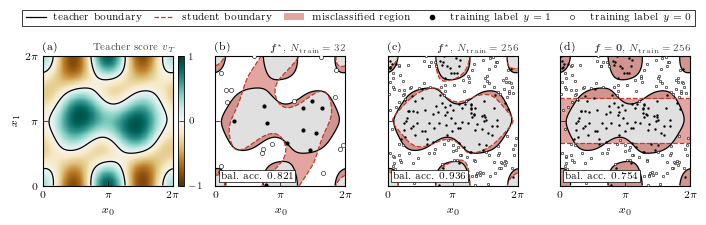

saved /home/felix/SAR-QML/notebooks/teacher_student_outputs/decision_boundary_paper.pdf


In [10]:
# =============================================================================
# Appendix figure: teacher decision boundary and what the students learn
# =============================================================================
# Refits students for one teacher and fold, using exactly the data, seeds and
# budget of the classification run, so the accuracies shown equal the
# corresponding rows of CLASSIFICATION_RESULTS. The last case is the no-query
# arm, whose score factorizes as g(x_0) h(x_1): its boundary consists of
# straight lines only. Needs the configuration, circuit, teacher and
# optimizer cells, and the plotting helpers from the manuscript-figure cell.
from mpl_toolkits.axes_grid1 import make_axes_locatable

BOUNDARY_TEACHER = 0
BOUNDARY_FOLD = 0
BOUNDARY_CASES = (("correct", 32), ("correct", 256), ("none", 256))
ERROR_COLOR = COLORS["correct"]
GRID_POINTS = 241
NEAR_BOUNDARY = 0.05

teacher = TEACHERS[BOUNDARY_TEACHER]
theta_teacher = teacher["full_parameters"]


def teacher_labels(x):
    return (np.asarray(forward(theta_teacher, x, F_STAR, CFG)) > 0).astype(float)


# The same test set and training pool as run_classification_experiment.
x_test = rng_from(BASE_SEED, 400, BOUNDARY_TEACHER).uniform(
    0, 2 * np.pi, (P["n_test"], CFG.n_qubits)
)
y_test = teacher_labels(x_test)
x_pool = rng_from(BASE_SEED, 401, BOUNDARY_TEACHER, BOUNDARY_FOLD).uniform(
    0, 2 * np.pi, (max(P["n_grid"]), CFG.n_qubits)
)
y_pool = teacher_labels(x_pool)

axis_values = np.linspace(0.0, 2 * np.pi, GRID_POINTS)
grid_x0, grid_x1 = np.meshgrid(axis_values, axis_values, indexing="xy")
grid_points = np.stack([grid_x0.ravel(), grid_x1.ravel()], axis=1)
teacher_grid = np.asarray(
    forward(theta_teacher, grid_points, F_STAR, CFG)
).reshape(grid_x0.shape)
teacher_test_score = np.asarray(forward(theta_teacher, x_test, F_STAR, CFG))

students = {}
for arm, n in BOUNDARY_CASES:
    f_arm = ARMS[arm]
    fit = fit_classifier(
        CFG,
        f_arm,
        x_pool[:n],
        y_pool[:n],
        x_test,
        y_test,
        seed=1_000_000 * BOUNDARY_TEACHER + 10_000 * BOUNDARY_FOLD + n,
    )
    theta_student = CFG.expand(fit["free_parameters"])
    student_grid = np.asarray(
        forward(theta_student, grid_points, f_arm, CFG)
    ).reshape(grid_x0.shape)
    wrong = (
        np.asarray(forward(theta_student, x_test, f_arm, CFG)) > 0
    ) != (y_test > 0)
    students[arm, n] = {
        "grid": student_grid,
        "accuracy": fit["test_balanced_accuracy"],
        "error_rate": float(np.mean(wrong)),
        # Share of misclassified test points that lie close to the teacher
        # boundary, against the share of all test points that do.
        "errors_near": float(np.mean(np.abs(teacher_test_score[wrong]) < NEAR_BOUNDARY)),
    }

boundary_mass = float(np.mean(np.abs(teacher_test_score) < NEAR_BOUNDARY))
print(
    f"teacher {BOUNDARY_TEACHER}, fold {BOUNDARY_FOLD}: "
    f"{100 * boundary_mass:.1f}% of test inputs have |v_T| < {NEAR_BOUNDARY}"
)
for (arm, n), student in students.items():
    print(
        f"  {arm:7s} N={n:3d}: balanced accuracy {student['accuracy']:.3f}, "
        f"error rate {100 * student['error_rate']:.1f}%, "
        f"{100 * student['errors_near']:.0f}% of errors have |v_T| < {NEAR_BOUNDARY}"
    )


def angle_axis(axis, show_y=True):
    ticks = [0.0, np.pi, 2 * np.pi]
    labels = [r"$0$", r"$\pi$", r"$2\pi$"]
    axis.set_xlim(0.0, 2 * np.pi)
    axis.set_ylim(0.0, 2 * np.pi)
    axis.set_aspect("equal")
    axis.set_xticks(ticks)
    axis.set_xticklabels(labels)
    axis.set_yticks(ticks)
    axis.set_yticklabels(labels if show_y else [])
    axis.set_xlabel(r"$x_0$")
    if show_y:
        axis.set_ylabel(r"$x_1$")
    axis.tick_params(which="both", top=False, right=False)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)


configure_matplotlib()
fig, axes = plt.subplots(1, 1 + len(BOUNDARY_CASES), figsize=(7.08, 2.25))
colorbar_axes = [
    make_axes_locatable(axis).append_axes("right", size="5%", pad=0.05)
    for axis in axes
]

# (a) Continuous teacher score and its zero level set
axis = axes[0]
image = axis.pcolormesh(
    grid_x0, grid_x1, teacher_grid,
    cmap="BrBG", vmin=-1.0, vmax=1.0, shading="auto", rasterized=True,
)
axis.contour(grid_x0, grid_x1, teacher_grid, levels=[0.0], colors="black", linewidths=0.9)
angle_axis(axis)
panel_title(axis, "(a)", r"Teacher score $v_T$")
colorbar = fig.colorbar(image, cax=colorbar_axes[0], ticks=[-1, 0, 1])
colorbar.outline.set_linewidth(0.6)
colorbar.ax.tick_params(labelsize=7)

# (b-d) Learned boundary against the teacher boundary
QUERY_TEXT = {
    "correct": r"$\boldsymbol{f}^\star$",
    "wrong": r"$2\boldsymbol{f}^\star$",
    "none": r"$\boldsymbol{f}=\boldsymbol{0}$",
}
teacher_positive = teacher_grid > 0
for axis, cax, letter, (arm, n) in zip(
    axes[1:], colorbar_axes[1:], ("(b)", "(c)", "(d)", "(e)"), BOUNDARY_CASES
):
    student = students[arm, n]
    disagreement = (student["grid"] > 0) != teacher_positive
    # Teacher classes in two light greys, disagreement on top in the arm colour.
    axis.pcolormesh(
        grid_x0, grid_x1, teacher_positive.astype(float),
        cmap=mpl.colors.ListedColormap(["white", "0.88"]),
        vmin=0, vmax=1, shading="auto", rasterized=True,
    )
    axis.pcolormesh(
        grid_x0, grid_x1, np.ma.masked_where(~disagreement, disagreement),
        cmap=mpl.colors.ListedColormap([ERROR_COLOR]),
        alpha=0.45, shading="auto", rasterized=True,
    )
    axis.contour(grid_x0, grid_x1, teacher_grid, levels=[0.0], colors="black", linewidths=0.9)
    axis.contour(
        grid_x0, grid_x1, student["grid"], levels=[0.0],
        colors=ERROR_COLOR, linewidths=0.9, linestyles="--",
    )
    positive = y_pool[:n] > 0
    marker_size = 9 if n <= 64 else 3
    axis.scatter(
        x_pool[:n][positive, 0], x_pool[:n][positive, 1],
        s=marker_size, c="black", lw=0, zorder=3,
    )
    axis.scatter(
        x_pool[:n][~positive, 0], x_pool[:n][~positive, 1],
        s=marker_size, facecolors="white", edgecolors="black", lw=0.4, zorder=3,
    )
    axis.text(
        0.04, 0.04,
        rf"bal.\ acc.\ ${student['accuracy']:.3f}$" if USE_TEX
        else f"bal. acc. {student['accuracy']:.3f}",
        transform=axis.transAxes, ha="left", va="bottom", fontsize=6.8,
        bbox=dict(facecolor="white", edgecolor="black", linewidth=0.5, pad=1.5),
        zorder=4,
    )
    angle_axis(axis, show_y=False)
    panel_title(axis, letter, QUERY_TEXT[arm] + rf", $N_{{\rm train}}={n}$")
    cax.set_visible(False)

legend_handles = [
    Line2D([], [], color="black", lw=0.9, label="teacher boundary"),
    Line2D([], [], color=ERROR_COLOR, lw=0.9, ls="--", label="student boundary"),
    Patch(facecolor=ERROR_COLOR, alpha=0.45, label="misclassified region"),
    Line2D([], [], ls="", marker="o", ms=3.0, color="black", label=r"training label $y=1$"),
    Line2D([], [], ls="", marker="o", ms=3.0, mfc="white", mec="black", mew=0.4, label=r"training label $y=0$"),
]
legend = fig.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
    ncol=5, frameon=True, framealpha=0.9, edgecolor="black", fancybox=False,
)
legend.get_frame().set_linewidth(0.6)
fig.subplots_adjust(left=0.055, right=0.985, bottom=0.17, top=0.80, wspace=0.22)

boundary_stem = OUTDIR / f"decision_boundary_{PROFILE}"
fig.savefig(boundary_stem.with_suffix(".pdf"), pad_inches=0.05, bbox_inches="tight", dpi=400)
fig.savefig(boundary_stem.with_suffix(".png"), pad_inches=0.05, bbox_inches="tight", dpi=400)
plt.show()
print(f"saved {boundary_stem.with_suffix('.pdf').resolve()}")